# 1. Data Import & Engineering (cyber-attacks-dataset)

**Dataset:** cyber-attacks-dataset - bidirectional network flows extracted with NFStream from the thesis laboratory captures and labeled from the attackers' attacklog records (`BENIGN` or the attack name).
**Goal:** Load, clean, explore, and prepare the data for the Standard ML and Graph ML notebooks.

**Outputs:** `prepared_data/ml_prepared.parquet`, `prepared_data/tl_prepared.parquet` and `prepared_data/metadata.json` for downstream notebooks.

The two prepared tables play the roles of the two CIC-IDS2017 directories used by the original CIC-IDS2017 notebooks:

| Table | CIC-IDS2017 counterpart | Content |
|---|---|---|
| `ml_prepared` | MachineLearningCVE | Flow features + labels, duplicate rows removed |
| `tl_prepared` | TrafficLabelling | Every flow: features + labels + `src_ip`, `dst_ip`, `src_port`, `bidirectional_first_seen_ms`, `capture_id` for graph construction and time-based splits |

## Configuration

All configurable settings for this notebook are defined below using Pydantic models.
Edit these values before running to customize behavior.

In [1]:
import os
from pydantic import BaseModel, Field
from typing import List, Optional

DEFAULT_DATASET_CSV = "../data/release/cyber-attacks-dataset/cyber_attacks_flows_labeled.csv"


class DataPathsConfig(BaseModel):
    """Path to the labeled release CSV and output directory."""
    dataset_csv: str = Field(default=os.environ.get("CYBER_ATTACKS_CSV", DEFAULT_DATASET_CSV),
                             description="Labeled release CSV, relative to this notebook or absolute (env: CYBER_ATTACKS_CSV)")
    output_dir: str = Field(default="prepared_data", description="Directory to save prepared data")


class DataPrepConfig(BaseModel):
    """Data preparation settings."""
    sample_rows: Optional[int] = Field(default=None, description="Stratified subsample for a quick trial run (e.g. 200_000); None = all flows")
    multiclass_target: str = Field(default="Technique", description="Multi-class target: 'Technique' (attack technique) or 'Label' (attack name)")
    use_splt_features: bool = Field(default=True, description="Use the first-20-packet sequence (splt_direction/ps/piat_ms_0..19) as features")
    categorical_features: List[str] = Field(default=["application_name", "application_category_name"],
                                            description="nDPI string columns encoded as integer codes")
    remove_duplicates: bool = Field(default=True, description="Remove duplicate rows from datasets")
    drop_constant_columns: bool = Field(default=True, description="Drop columns with zero variance")
    drop_redundant_columns: bool = Field(default=True, description="Drop perfectly correlated columns (|r|=1.0)")
    save_prepared_data: bool = Field(default=True, description="Save the prepared dataframes (Parquet)")
    random_state: int = Field(default=42, description="Random seed for sampling")


class CorrelationFeatureSelectionConfig(BaseModel):
    """Feature selection based on correlation with the target."""
    enabled: bool = Field(default=True, description="Enable correlation-based feature selection")
    correlation_threshold: float = Field(default=0.3, description="Min |correlation| with target to keep a feature")
    method: str = Field(default="spearman", description="Correlation method: 'pearson' or 'spearman'")
    target: str = Field(default="binary", description="'binary' (BENIGN vs ATTACK) or 'label_encoded' (multi-class codes, no natural order)")


class EDAConfig(BaseModel):
    """EDA visualization settings."""
    run_eda: bool = Field(default=True, description="Run EDA visualizations")
    plot_sample_rows: int = Field(default=300_000, description="Flows sampled for the histograms")
    key_features: List[str] = Field(
        default=[
            'bidirectional_duration_ms', 'src2dst_packets', 'dst2src_packets',
            'src2dst_bytes', 'dst2src_bytes',
            'bidirectional_bps', 'bidirectional_pps', 'src2dst_mean_ps',
            'dst2src_mean_ps', 'bidirectional_mean_piat_ms', 'dst_port',
            'bidirectional_mean_ps'
        ],
        description="Features to visualize in histograms (max 12; NFStream equivalents of the CIC-IDS2017 selection)"
    )

paths_cfg = DataPathsConfig()
prep_cfg = DataPrepConfig()
corr_cfg = CorrelationFeatureSelectionConfig()
eda_cfg = EDAConfig()

print("Configuration loaded:")
print(f"  Paths: dataset={paths_cfg.dataset_csv}, Output={paths_cfg.output_dir}")
print(f"  Prep: sample_rows={prep_cfg.sample_rows}, multiclass_target={prep_cfg.multiclass_target}, splt={prep_cfg.use_splt_features}")
print(f"        duplicates={prep_cfg.remove_duplicates}, constants={prep_cfg.drop_constant_columns}, redundant={prep_cfg.drop_redundant_columns}")
print(f"  Correlation selection: enabled={corr_cfg.enabled}, threshold={corr_cfg.correlation_threshold}, method={corr_cfg.method}, target={corr_cfg.target}")
print(f"  EDA: enabled={eda_cfg.run_eda}")
print(f"  Save: {prep_cfg.save_prepared_data}")

Configuration loaded:
  Paths: dataset=../data/release/cyber-attacks-dataset/cyber_attacks_flows_labeled.csv, Output=prepared_data
  Prep: sample_rows=None, multiclass_target=Technique, splt=True
        duplicates=True, constants=True, redundant=True
  Correlation selection: enabled=True, threshold=0.3, method=spearman, target=binary
  EDA: enabled=True
  Save: True


## 1.1 Setup & Imports

In [2]:
import gc
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

NOTEBOOK_T0 = time.time()

def resolve_existing_path(path_str: str) -> Path:
    p = Path(path_str)
    if p.exists():
        return p

    cwd = Path.cwd()
    for base in [cwd, cwd.parent, cwd.parent.parent]:
        candidate = base / path_str
        if candidate.exists():
            return candidate

    raise FileNotFoundError(f"Path not found: {path_str}")


print("All imports successful.")

All imports successful.


## 2. Load the Dataset

The release CSV has 188 columns. Columns that identify a flow, host, pcap file or absolute time are not loaded, except the five context columns kept in the TL table; free-text application metadata, stitching artefacts and the JSON list copies of the packet sequence are skipped as well.

In [3]:
LABEL_COL = 'label'
BENIGN = 'BENIGN'

# Columns that identify a flow, host, pcap file or absolute time rather than describing traffic.
# They never become model features (see ../flow-extraction/DATA_DICTIONARY.md).
IDENTIFYING_COLS = [
    'id', 'flow_id', 'canonical_key', 'fragment_id', 'fragment_ids', 'source_pcap', 'source_pcaps',
    'expiration_id', 'src_ip', 'dst_ip', 'src_mac', 'dst_mac', 'src_oui', 'dst_oui', 'src_port',
    'bidirectional_first_seen_ms', 'bidirectional_last_seen_ms',
    'src2dst_first_seen_ms', 'src2dst_last_seen_ms', 'dst2src_first_seen_ms', 'dst2src_last_seen_ms',
    'start_date', 'start_hour', 'start_minute', 'start_day_of_week', 'capture_id',
]
# Kept in the TL table only: graph endpoints, time-based splits, capture of origin.
TL_CONTEXT_COLS = ['src_ip', 'dst_ip', 'src_port', 'bidirectional_first_seen_ms', 'capture_id']
# Artefacts of stitching flows across the capture's 10-minute pcap rotation, not traffic properties.
PROVENANCE_COLS = ['n_fragments', 'recut_active_timeout', 'truncated_start', 'truncated_end']
# Free-text application metadata (hostnames, user agents, TLS fingerprints).
TEXT_COLS = ['requested_server_name', 'client_fingerprint', 'server_fingerprint', 'user_agent', 'content_type']
# JSON list copies of the flat splt_*_0..19 columns.
LIST_COLS = ['splt_direction', 'splt_ps', 'splt_piat_ms']

# Attack technique derived from the attack name (same rules as ../dataset-analysis/analyze_dataset.py).
FULL_SCAN = 'nmap-full-portscan'
TECHNIQUE_RULES = (
    ('-revshell', 'Remote code execution (reverse shell)'),
    ('sqlmap', 'SQL injection'),
    ('sqli', 'SQL injection'),
    ('xss', 'Cross-site scripting'),
    ('cmdinject', 'OS command injection'),
    ('lfi', 'Local file inclusion'),
    ('ssti', 'Server-side template injection'),
    ('wordlist', 'Brute force (wordlist)'),
    ('-dos', 'Denial of service'),
    ('-enum', 'Service enumeration'),
    ('cve-', 'Known-vulnerability exploit (CVE/CNVD)'),
    ('cnvd-', 'Known-vulnerability exploit (CVE/CNVD)'),
)


def technique(label):
    if label == BENIGN:
        return BENIGN
    if label == FULL_SCAN:
        return 'Port scan (full TCP range)'
    if label.endswith('-portscan'):
        return 'Service scan (single port, pre-exploit)'
    for key, name in TECHNIQUE_RULES:
        if key in label:
            return name
    return 'Other'


dataset_csv = resolve_existing_path(paths_cfg.dataset_csv)
header = pd.read_csv(dataset_csv, nrows=0).columns.tolist()

skip = set(LIST_COLS + TEXT_COLS + PROVENANCE_COLS) | (set(IDENTIFYING_COLS) - set(TL_CONTEXT_COLS))
if not prep_cfg.use_splt_features:
    skip |= {c for c in header if c.startswith('splt_')}
load_cols = [c for c in header if c not in skip]

print(f"Loading {dataset_csv} ({len(load_cols)} of {len(header)} columns)")
t0 = time.time()
# pyarrow's reader is fast and keeps capture ids such as "07" as strings
df = pacsv.read_csv(dataset_csv, convert_options=pacsv.ConvertOptions(
    include_columns=load_cols, column_types={'capture_id': pa.string()})).to_pandas()
df = df.rename(columns={LABEL_COL: 'Label'})
df['Technique'] = df['Label'].map({lbl: technique(lbl) for lbl in df['Label'].unique()})

print(f"Loaded in {time.time() - t0:.0f}s")
print(f"\nTotal rows: {df.shape[0]:,} \nTotal columns: {df.shape[1]}")

Loading ../data/release/cyber-attacks-dataset/cyber_attacks_flows_labeled.csv (155 of 188 columns)


Loaded in 14s

Total rows: 2,263,421 
Total columns: 156


In [4]:
def stratified_sample(df, n, label_col, random_state, keep_whole_below=50):
    """About n rows with every class's share preserved; classes smaller than keep_whole_below stay whole."""
    frac = n / len(df)
    parts = []
    for _, g in df.groupby(label_col, sort=False):
        k = len(g) if len(g) < keep_whole_below else max(keep_whole_below, round(len(g) * frac))
        parts.append(g.sample(n=min(k, len(g)), random_state=random_state))
    return pd.concat(parts).sort_index()


if prep_cfg.sample_rows and prep_cfg.sample_rows < len(df):
    n_before = len(df)
    df = stratified_sample(df, prep_cfg.sample_rows, 'Label', prep_cfg.random_state).reset_index(drop=True)
    print(f"Stratified sample: {len(df):,} of {n_before:,} flows\n")

print(f"Sample rows:")
df.head()

Sample rows:


,src_ip,src_port,dst_ip,dst_port,protocol,ip_version,vlan_id,tunnel_id,bidirectional_first_seen_ms,bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,src2dst_max_ps,dst2src_min_ps,dst2src_mean_ps,dst2src_stddev_ps,dst2src_max_ps,bidirectional_min_piat_ms,bidirectional_mean_piat_ms,bidirectional_stddev_piat_ms,bidirectional_max_piat_ms,src2dst_min_piat_ms,src2dst_mean_piat_ms,src2dst_stddev_piat_ms,src2dst_max_piat_ms,dst2src_min_piat_ms,dst2src_mean_piat_ms,dst2src_stddev_piat_ms,dst2src_max_piat_ms,bidirectional_syn_packets,bidirectional_cwr_packets,bidirectional_ece_packets,bidirectional_urg_packets,bidirectional_ack_packets,bidirectional_psh_packets,bidirectional_rst_packets,bidirectional_fin_packets,...,splt_ps_4,splt_piat_ms_4,splt_direction_5,splt_ps_5,splt_piat_ms_5,splt_direction_6,splt_ps_6,splt_piat_ms_6,splt_direction_7,splt_ps_7,splt_piat_ms_7,splt_direction_8,splt_ps_8,splt_piat_ms_8,splt_direction_9,splt_ps_9,splt_piat_ms_9,splt_direction_10,splt_ps_10,splt_piat_ms_10,splt_direction_11,splt_ps_11,splt_piat_ms_11,splt_direction_12,splt_ps_12,splt_piat_ms_12,splt_direction_13,splt_ps_13,splt_piat_ms_13,splt_direction_14,splt_ps_14,splt_piat_ms_14,splt_direction_15,splt_ps_15,splt_piat_ms_15,splt_direction_16,splt_ps_16,splt_piat_ms_16,splt_direction_17,splt_ps_17,splt_piat_ms_17,splt_direction_18,splt_ps_18,splt_piat_ms_18,splt_direction_19,splt_ps_19,splt_piat_ms_19,capture_id,Label,Technique
0,192.168.77.253,0,224.0.0.22,0,2,4,1017,0,1784015121226,0,1,82,0,1,82,0,0,0,82.00,82.00,0.00,82.00,82.00,82.00,0.00,82.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,07,BENIGN,BENIGN
1,192.168.77.242,0,224.0.0.22,0,2,4,1017,0,1784015188947,0,1,82,0,1,82,0,0,0,82.00,82.00,0.00,82.00,82.00,82.00,0.00,82.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,07,BENIGN,BENIGN
2,192.168.77.246,0,224.0.0.22,0,2,4,1017,0,1784015188967,0,1,82,0,1,82,0,0,0,82.00,82.00,0.00,82.00,82.00,82.00,0.00,82.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,07,BENIGN,BENIGN
3,192.168.77.247,0,224.0.0.22,0,2,4,1017,0,1784015189217,0,1,82,0,1,82,0,0,0,82.00,82.00,0.00,82.00,82.00,82.00,0.00,82.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,07,BENIGN,BENIGN
4,192.168.77.240,0,224.0.0.22,0,2,4,1017,0,1784015189402,0,1,82,0,1,82,0,0,0,82.00,82.00,0.00,82.00,82.00,82.00,0.00,82.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,07,BENIGN,BENIGN


In [5]:
print("Class Distribution (Label)\n")
label_counts = df['Label'].value_counts()
print(label_counts.to_string())

print(f"\nTotal samples: {label_counts.sum():,}")
print(f"Unique labels: {df['Label'].nunique()}")

print(f"\nTechnique distribution:\n")
tech_counts = df['Technique'].value_counts()
print(pd.DataFrame({'flows': tech_counts, '%': (tech_counts / tech_counts.sum() * 100).round(3)}).to_string())

print(f"\nFlows per technique and capture:\n")
print(pd.crosstab(df['Technique'], df['capture_id'], margins=True).to_string())

print(f"\nUnique Source IPs: {df['src_ip'].nunique()}")
print(f"Unique Destination IPs: {df['dst_ip'].nunique()}")
print(f"Unique IPs: {pd.concat([df['src_ip'], df['dst_ip']]).nunique()}")

Class Distribution (Label)

Label
nmap-full-portscan                              1728220
BENIGN                                           464656
ms2-mutillidae-sqlmap                             53343
ms3-iis-ftp-wordlist                              15924
vulnhub-1panel-cve-2024-39907                       218
ms3-glassfish-revshell                              152
ms3-jenkins-revshell                                152
vulnhub-aj-report-cnvd-2024-15077                   142
vulnhub-activemq-cve-2022-41678                      85
ms3-iis-http-dos                                     53
ms2-dvwa-xss-reflected                               51
vulnhub-airflow-cve-2020-17526                       42
vulnhub-airflow-cve-2020-11978                       39
vulnhub-apache-druid-cve-2021-25646                  34
ms3-elasticsearch-revshell                           28
vulnhub-activemq-cve-2026-34197                      21
ms2-dvwa-sqli-manual                                 20
ms2-dvwa-xss-s

capture_id                                    07      10      All
Technique                                                        
BENIGN                                    382789   81867   464656
Brute force (wordlist)                     15402     522    15924
Cross-site scripting                          65       5       70
Denial of service                             53       0       53
Known-vulnerability exploit (CVE/CNVD)       330     271      601
Local file inclusion                           4       0        4
OS command injection                          13       0       13
Port scan (full TCP range)               1351575  376645  1728220
Remote code execution (reverse shell)        243     124      367
SQL injection                              45852    7511    53363
Server-side template injection                12       0       12
Service enumeration                            4       3        7
Service scan (single port, pre-exploit)      113      18      131
All       

## 3. Data Quality Check

In [6]:
print("Missing Values\n")
missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    print(pd.DataFrame({'missing': missing, '% of rows': (missing / len(df) * 100).round(2)}).to_string())
else:
    print("No missing values found.")

Missing Values



                      missing  % of rows
bytes_ratio_updown      64619       2.85
packets_ratio_updown    64619       2.85
bidirectional_pps     1415769      62.55
bidirectional_bps     1415769      62.55
src2dst_pps           1933924      85.44
src2dst_bps           1933924      85.44
dst2src_pps           1956985      86.46
dst2src_bps           1956985      86.46
splt_direction_1        41474       1.83
splt_ps_1               41474       1.83
splt_piat_ms_1          41474       1.83
splt_direction_2      1944704      85.92
splt_ps_2             1944704      85.92
splt_piat_ms_2        1944704      85.92
splt_direction_3      1948488      86.09
splt_ps_3             1948488      86.09
splt_piat_ms_3        1948488      86.09
splt_direction_4      1948930      86.11
splt_ps_4             1948930      86.11
splt_piat_ms_4        1948930      86.11
splt_direction_5      1948941      86.11
splt_ps_5             1948941      86.11
splt_piat_ms_5        1948941      86.11
splt_direction_6

In [7]:
# NFStream leaves these columns empty by design (../flow-extraction/DATA_DICTIONARY.md):
#   splt_*_0..19                -> positions past the flow's packet count
#   *_pps, *_bps                -> the flow (or that direction) lasted 0 ms
#   bytes/packets_ratio_updown  -> the dst->src direction carried nothing
# They are filled with -1 ("undefined"), the padding NFStream itself uses inside the splt lists.
# Dropping them like the CIC-IDS2017 notebook drops NaN rows would remove most scan flows.
FILL_VALUE = -1
undefined_by_design = [c for c in df.columns
                       if c.startswith('splt_') or c.endswith(('_pps', '_bps'))
                       or c in ('bytes_ratio_updown', 'packets_ratio_updown')]
df[undefined_by_design] = df[undefined_by_design].fillna(FILL_VALUE)
print(f"Filled undefined values with {FILL_VALUE} in {len(undefined_by_design)} columns")

for col in prep_cfg.categorical_features:
    if col in df.columns:
        df[col] = df[col].fillna('')

print("\nInfinite Values")
float_cols = [c for c in df.columns if pd.api.types.is_float_dtype(df[c])]
inf_counts = {c: int(np.isinf(df[c]).sum()) for c in float_cols}
inf_counts = {c: n for c, n in inf_counts.items() if n > 0}
if inf_counts:
    for col, cnt in inf_counts.items():
        print(f"  {col}: {cnt} infinite values")
    df[list(inf_counts)] = df[list(inf_counts)].replace([np.inf, -np.inf], np.nan)
else:
    print("No infinite values in numeric columns.")

rows_before = len(df)
df = df.dropna()
print(f"\nDropped {rows_before - len(df):,} rows with remaining missing values")
print(f"Remaining: {len(df):,} rows")

Filled undefined values with -1 in 68 columns

Infinite Values
No infinite values in numeric columns.



Dropped 0 rows with remaining missing values
Remaining: 2,263,421 rows


In [8]:
non_feature_cols = TL_CONTEXT_COLS + ['Label', 'Technique']
categorical_cols = [c for c in prep_cfg.categorical_features if c in df.columns]

bool_cols = df.select_dtypes(include='bool').columns.tolist()
for col in bool_cols:
    df[col] = df[col].astype(np.int8)

categorical_mappings = {}
for col in categorical_cols:
    cat = df[col].astype('category')
    categorical_mappings[col] = cat.cat.categories.astype(str).tolist()
    df[col] = cat.cat.codes.astype(np.int32)

unexpected = [c for c in df.columns if c not in non_feature_cols and not pd.api.types.is_numeric_dtype(df[c])]
if unexpected:
    print(f"Dropping non-numeric columns not configured as categorical: {unexpected}")
    df = df.drop(columns=unexpected)

feature_candidates = [c for c in df.columns if c not in non_feature_cols]
print(f"Boolean columns converted to 0/1: {len(bool_cols)}")
print(f"Categorical columns encoded: {categorical_cols}")
print(f"Feature candidates: {len(feature_candidates)}")

# ML table: features + labels (MachineLearningCVE). TL table: every flow with its context (TrafficLabelling).
ml_df = df[feature_candidates + ['Label', 'Technique']].copy()
tl_df = df
del df
gc.collect()
print(f"\nml_df: {ml_df.shape}, tl_df: {tl_df.shape}")

Boolean columns converted to 0/1: 13
Categorical columns encoded: ['application_name', 'application_category_name']
Feature candidates: 149



ml_df: (2263421, 151), tl_df: (2263421, 156)


In [9]:
ml_dup_mask = ml_df.duplicated()
tl_dup_mask = tl_df.duplicated()
print(f"ML dataset: {int(ml_dup_mask.sum()):,} duplicate rows (identical features and label)")
print(f"TL dataset: {int(tl_dup_mask.sum()):,} duplicate rows (identical features, label and context)")

print("\nML dataset - per label duplicate rows:")
ml_label_counts = ml_df['Label'].value_counts()
ml_dup_per_label = ml_df.loc[ml_dup_mask, 'Label'].value_counts()
for label, count in ml_dup_per_label.items():
    print(f"  {label}: {count:,} of {ml_label_counts[label]:,}")

ML dataset: 1,633,742 duplicate rows (identical features and label)
TL dataset: 0 duplicate rows (identical features, label and context)

ML dataset - per label duplicate rows:
  nmap-full-portscan: 1,238,390 of 1,728,220
  BENIGN: 395,294 of 464,656
  ms3-iis-ftp-wordlist: 37 of 15,924
  vulnhub-flask-ssti: 7 of 12
  vulnhub-airflow-cve-2020-17526: 6 of 42
  vulnhub-flask-ssti-portscan: 4 of 7
  ms3-iis-http-dos: 2 of 53
  vulnhub-aj-report-cnvd-2024-15077: 1 of 142
  ms3-snmp-portscan: 1 of 5


In [10]:
if prep_cfg.remove_duplicates:
    print("Removing duplicate rows\n")

    ml_before, tl_before = len(ml_df), len(tl_df)
    ml_df = ml_df[~ml_dup_mask].reset_index(drop=True)
    tl_df = tl_df[~tl_dup_mask].reset_index(drop=True)
    print(f"ML dataset: {ml_before - len(ml_df):,} removed, {len(ml_df):,} remaining")
    print(f"TL dataset: {tl_before - len(tl_df):,} removed, {len(tl_df):,} remaining")

del ml_dup_mask, tl_dup_mask
gc.collect();

Removing duplicate rows



ML dataset: 1,633,742 removed, 629,679 remaining
TL dataset: 0 removed, 2,263,421 remaining


In [11]:
print("Constant and Near-Zero Variance Columns - ML dataset")

constant_cols = []
low_var_cols = []

for col in feature_candidates:
    n_unique = ml_df[col].nunique()
    if n_unique <= 1:
        constant_cols.append(col)
    elif n_unique <= 3:
        low_var_cols.append((col, n_unique, ml_df[col].std()))

if constant_cols:
    print(f"Constant columns")
    for c in constant_cols:
        print(f"  {c} value: {ml_df[c].iloc[0]}")
else:
    print("No constant columns found.")

if low_var_cols:
    print(f"Very low variance columns (2 to 3 unique values):")
    for c, nuniq, std in low_var_cols:
        print(f"  {c}  (unique: {nuniq}, std: {std:.6f})")

Constant and Near-Zero Variance Columns - ML dataset


Constant columns
  vlan_id value: 1017
  bidirectional_cwr_packets value: 0
  bidirectional_ece_packets value: 0
  src2dst_cwr_packets value: 0
  src2dst_ece_packets value: 0
  src2dst_urg_packets value: 0
  dst2src_cwr_packets value: 0
  dst2src_ece_packets value: 0
  src_is_multicast value: 0
  src_is_broadcast value: 0
  dst_is_broadcast value: 0
  splt_direction_0 value: 0
  splt_piat_ms_0 value: 0.0
Very low variance columns (2 to 3 unique values):
  ip_version  (unique: 2, std: 0.045912)
  tunnel_id  (unique: 2, std: 0.011955)
  application_is_guessed  (unique: 2, std: 0.073380)
  application_confidence  (unique: 3, std: 2.422653)
  is_ipv4  (unique: 2, std: 0.022956)
  is_ipv6  (unique: 2, std: 0.022956)
  is_tcp  (unique: 2, std: 0.231093)
  is_udp  (unique: 2, std: 0.224524)
  is_other_protocol  (unique: 2, std: 0.057886)
  src_is_private  (unique: 2, std: 0.023059)
  dst_is_private  (unique: 2, std: 0.229560)
  dst_is_multicast  (unique: 2, std: 0.070026)
  src_port_wellknown

## 4. Exploratory Data Analysis (EDA)

Computed on the deduplicated ML dataset, as in the CIC-IDS2017 notebook. Class plots use the multi-class target set in the configuration.

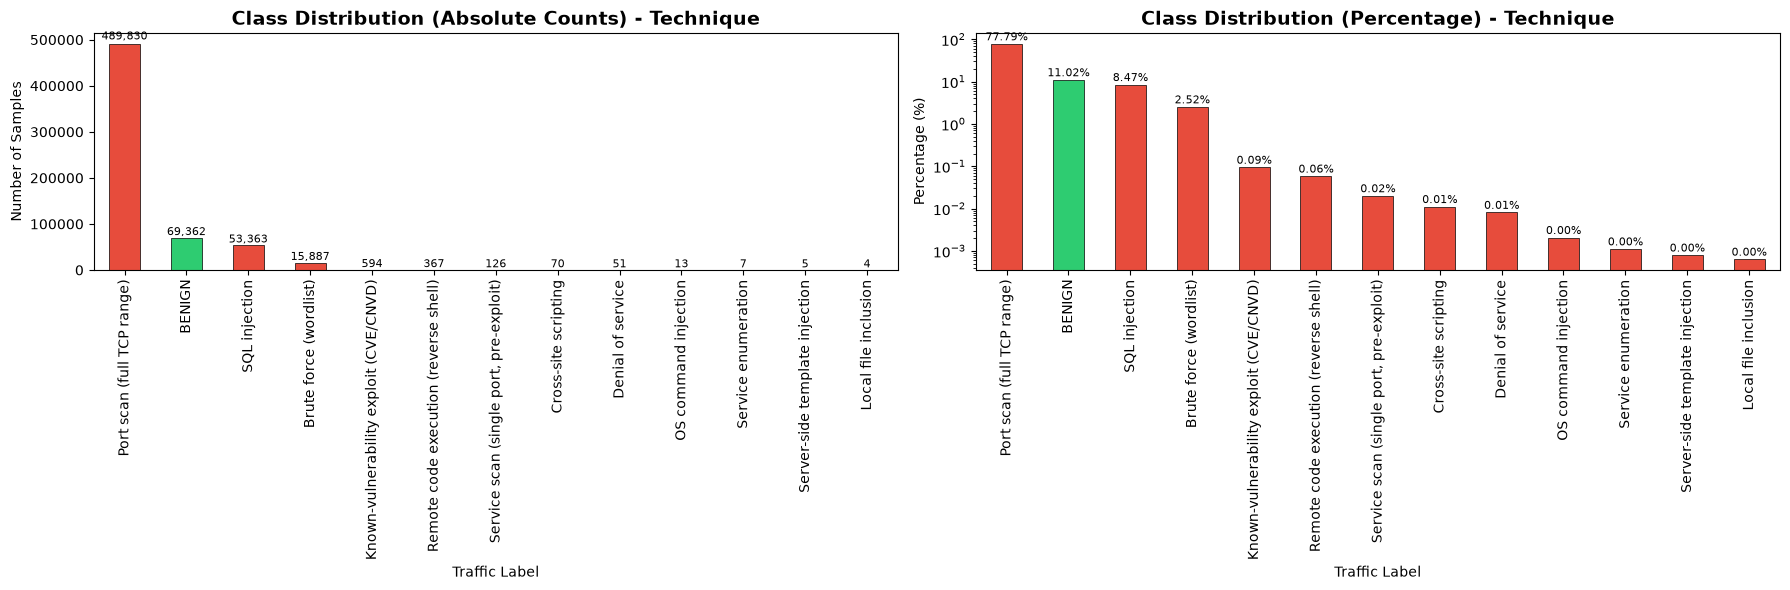

In [12]:
target_col = prep_cfg.multiclass_target

if eda_cfg.run_eda:
    # Class Distribution Bar Chart
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    label_counts = ml_df[target_col].value_counts()
    colors = ['#2ecc71' if label == BENIGN else '#e74c3c' for label in label_counts.index]
    label_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black', linewidth=0.5)
    axes[0].set_title(f'Class Distribution (Absolute Counts) - {target_col}', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Number of Samples')
    axes[0].set_xlabel('Traffic Label')
    axes[0].tick_params(axis='x', rotation=90)
    for i, (val, name) in enumerate(zip(label_counts.values, label_counts.index)):
        axes[0].text(i, val + val * 0.01, f'{val:,}', ha='center', va='bottom', fontsize=8)

    label_pct = (label_counts / label_counts.sum() * 100)
    label_pct.plot(kind='bar', ax=axes[1], color=colors, edgecolor='black', linewidth=0.5)
    axes[1].set_title(f'Class Distribution (Percentage) - {target_col}', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Percentage (%)')
    axes[1].set_xlabel('Traffic Label')
    axes[1].set_yscale('log')
    axes[1].tick_params(axis='x', rotation=90)
    for i, (val, name) in enumerate(zip(label_pct.values, label_pct.index)):
        axes[1].text(i, val + val * 0.05, f'{val:.2f}%', ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.show()
else:
    print("EDA visualizations DISABLED.")

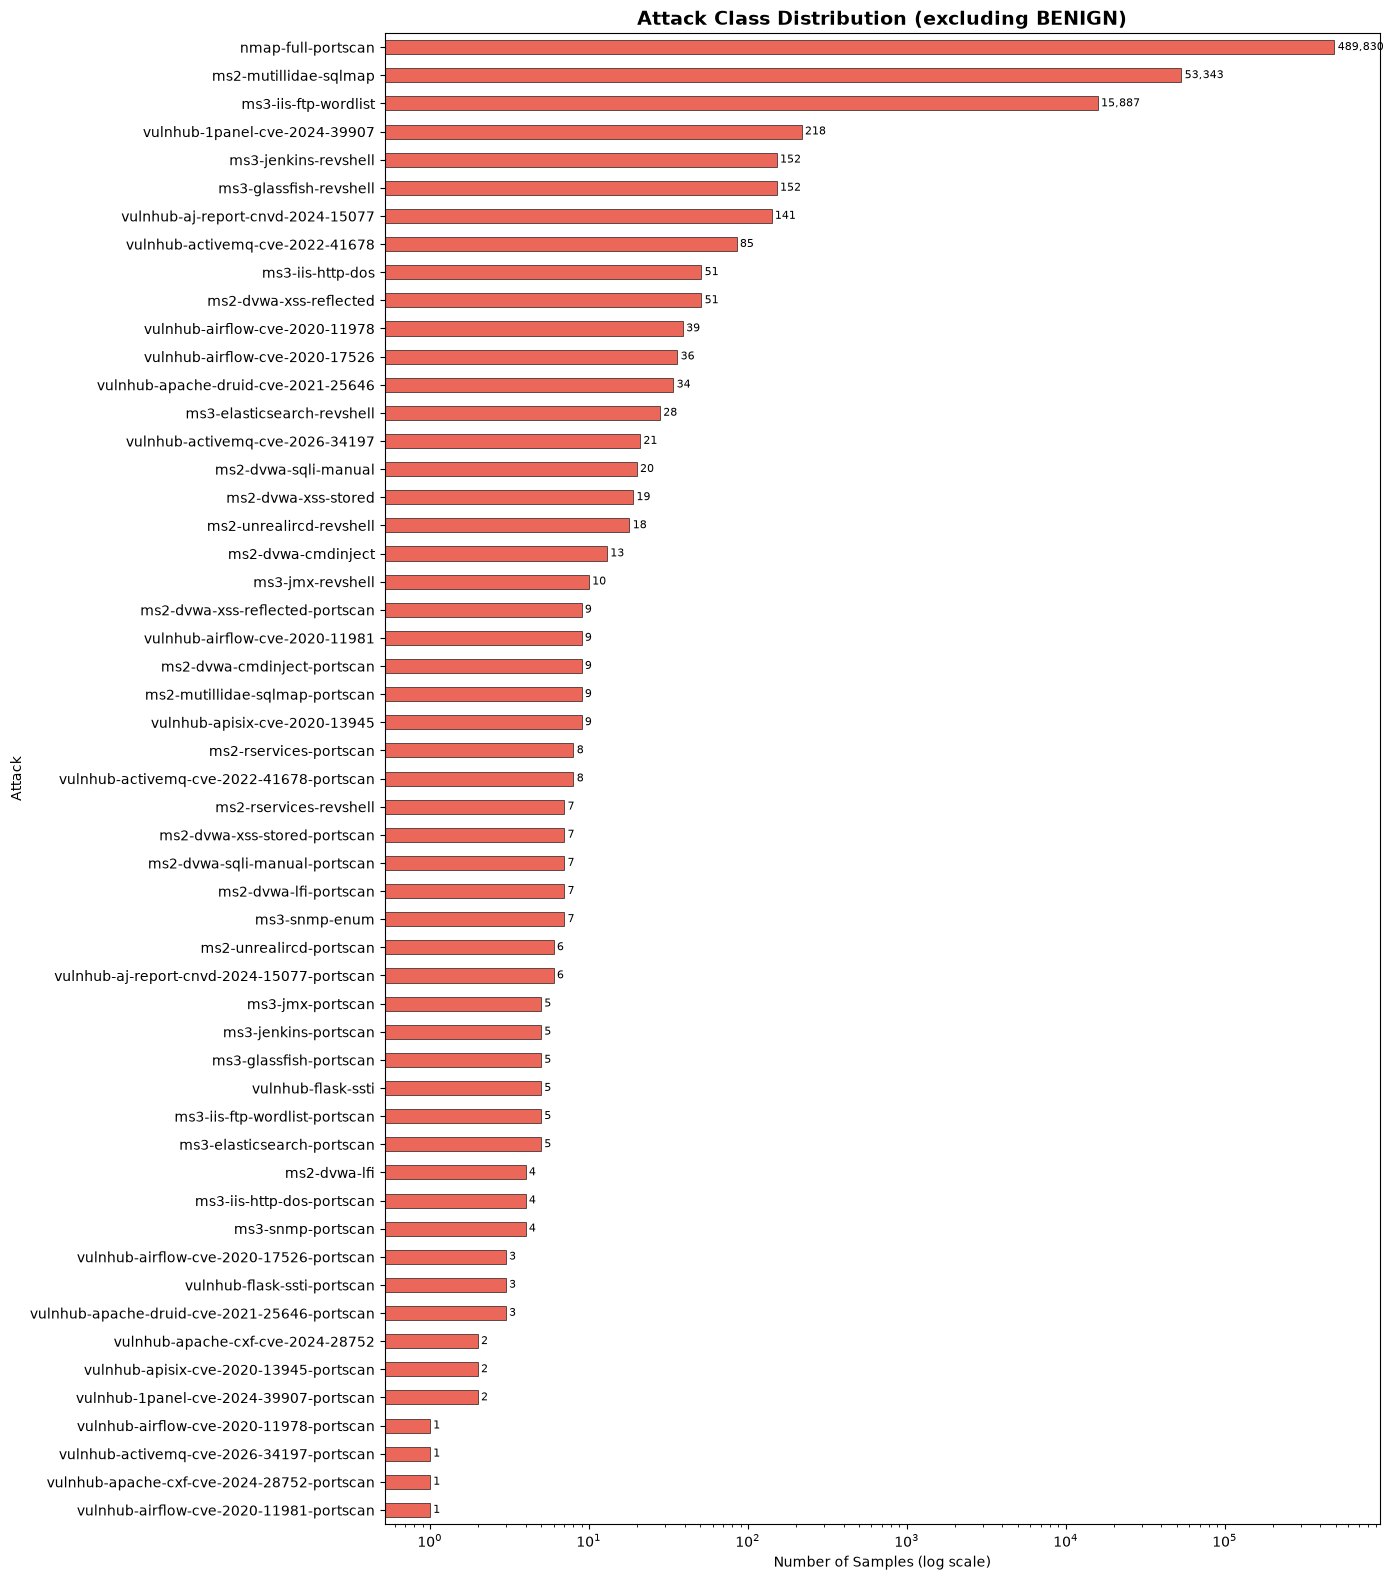

In [13]:
if eda_cfg.run_eda:
    # Attack classes only (attack names; log scale, the largest class is orders of magnitude above the median)
    attack_counts = ml_df.loc[ml_df['Label'] != BENIGN, 'Label'].value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(14, max(5, 0.3 * len(attack_counts))))
    attack_counts.plot(kind='barh', ax=ax, color='#e74c3c', edgecolor='black', linewidth=0.5, alpha=0.85)
    ax.set_xscale('log')
    ax.set_title('Attack Class Distribution (excluding BENIGN)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Number of Samples (log scale)')
    ax.set_ylabel('Attack')
    for i, val in enumerate(attack_counts.values):
        ax.text(val * 1.05, i, f'{val:,}', va='center', fontsize=8)
    plt.tight_layout()
    plt.show()

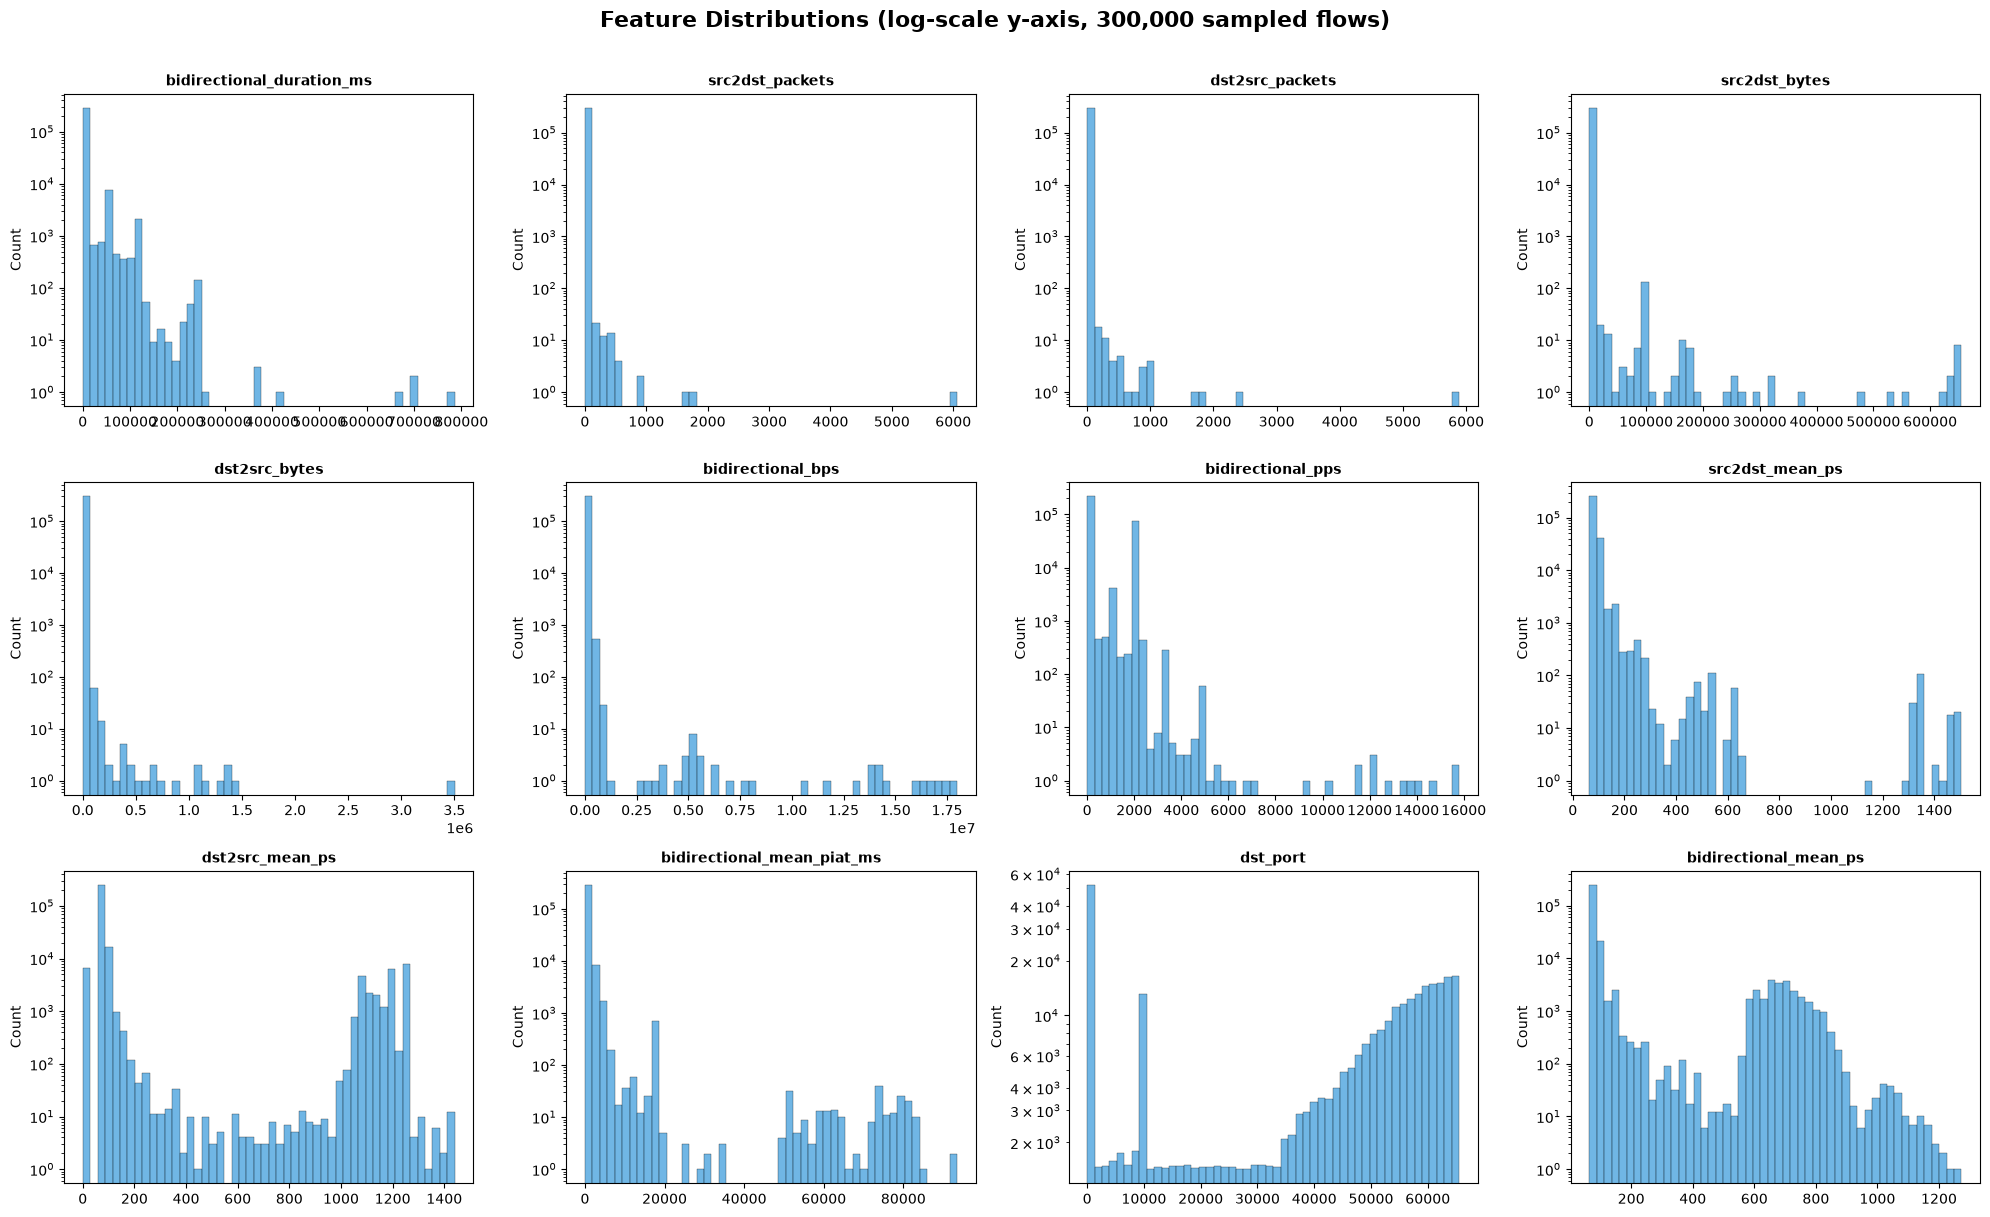

In [14]:
if eda_cfg.run_eda:
    # Feature Distributions - Histograms for key features (random sample of flows)
    key_features = [f for f in eda_cfg.key_features if f in ml_df.columns][:12]
    plot_df = ml_df.sample(n=min(eda_cfg.plot_sample_rows, len(ml_df)), random_state=prep_cfg.random_state)

    fig, axes = plt.subplots(3, 4, figsize=(20, 12))
    axes = axes.flatten()

    for i, feat in enumerate(key_features):
        ax = axes[i]
        data = plot_df[feat].clip(lower=0)
        ax.hist(data, bins=50, color='#3498db', edgecolor='black', linewidth=0.3, alpha=0.7)
        ax.set_title(feat, fontsize=10, fontweight='bold')
        ax.set_ylabel('Count')
        ax.set_yscale('log')

    for j in range(len(key_features), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Feature Distributions (log-scale y-axis, {len(plot_df):,} sampled flows)', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

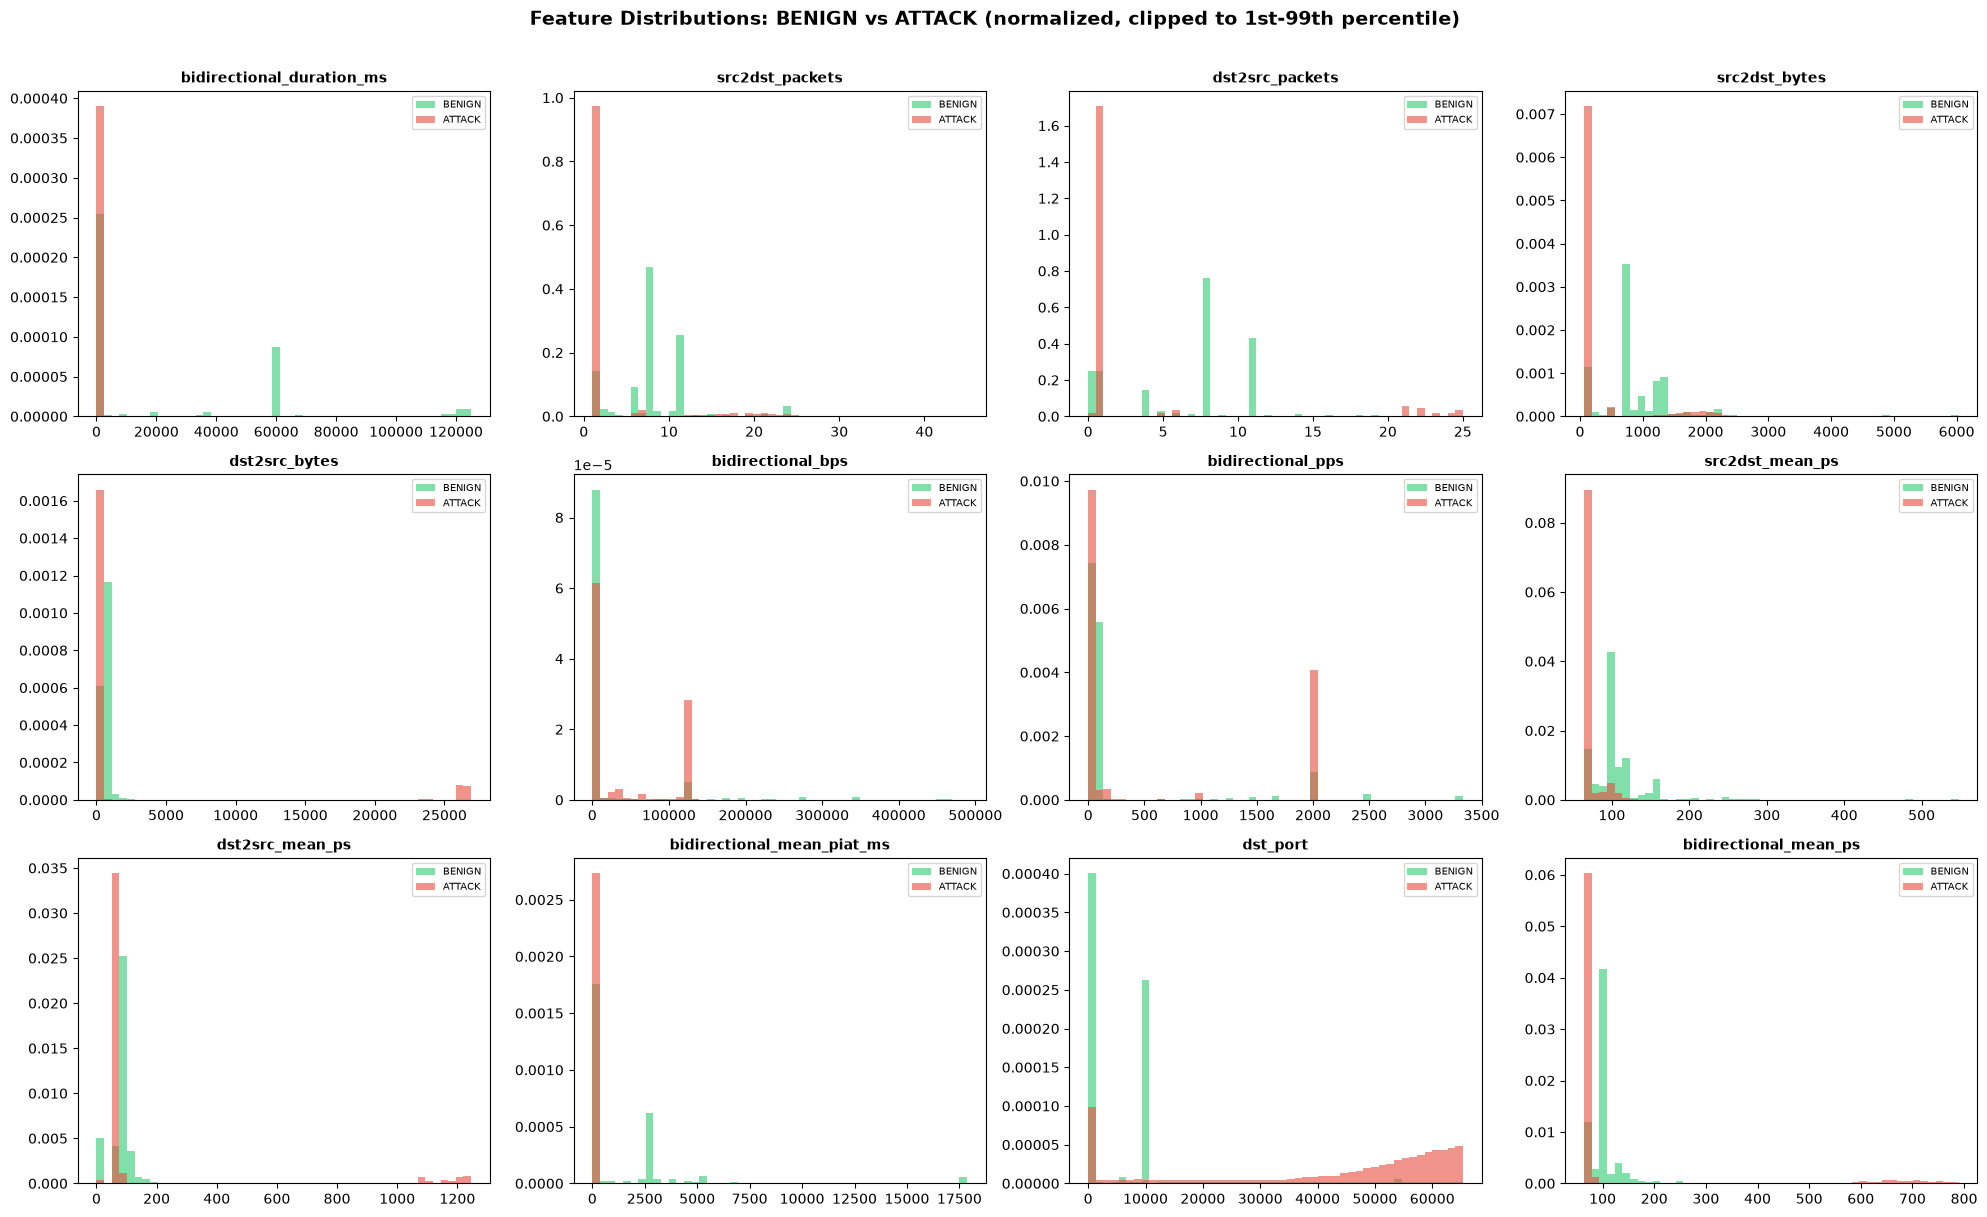

In [15]:
if eda_cfg.run_eda:
    # Feature distributions - Normal vs Attack comparison
    is_attack = plot_df['Label'] != BENIGN

    fig, axes = plt.subplots(3, 4, figsize=(20, 12))
    axes = axes.flatten()

    for i, feat in enumerate(key_features):
        ax = axes[i]
        benign_data = plot_df.loc[~is_attack, feat]
        attack_data = plot_df.loc[is_attack, feat]

        low = min(benign_data.quantile(0.01), attack_data.quantile(0.01))
        high = max(benign_data.quantile(0.99), attack_data.quantile(0.99))
        if high <= low:
            high = low + 1
        bins = np.linspace(low, high, 50)

        ax.hist(benign_data, bins=bins, alpha=0.6, label='BENIGN', color='#2ecc71', density=True)
        ax.hist(attack_data, bins=bins, alpha=0.6, label='ATTACK', color='#e74c3c', density=True)
        ax.set_title(feat, fontsize=10, fontweight='bold')
        ax.legend(fontsize=7)

    for j in range(len(key_features), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle('Feature Distributions: BENIGN vs ATTACK (normalized, clipped to 1st-99th percentile)',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

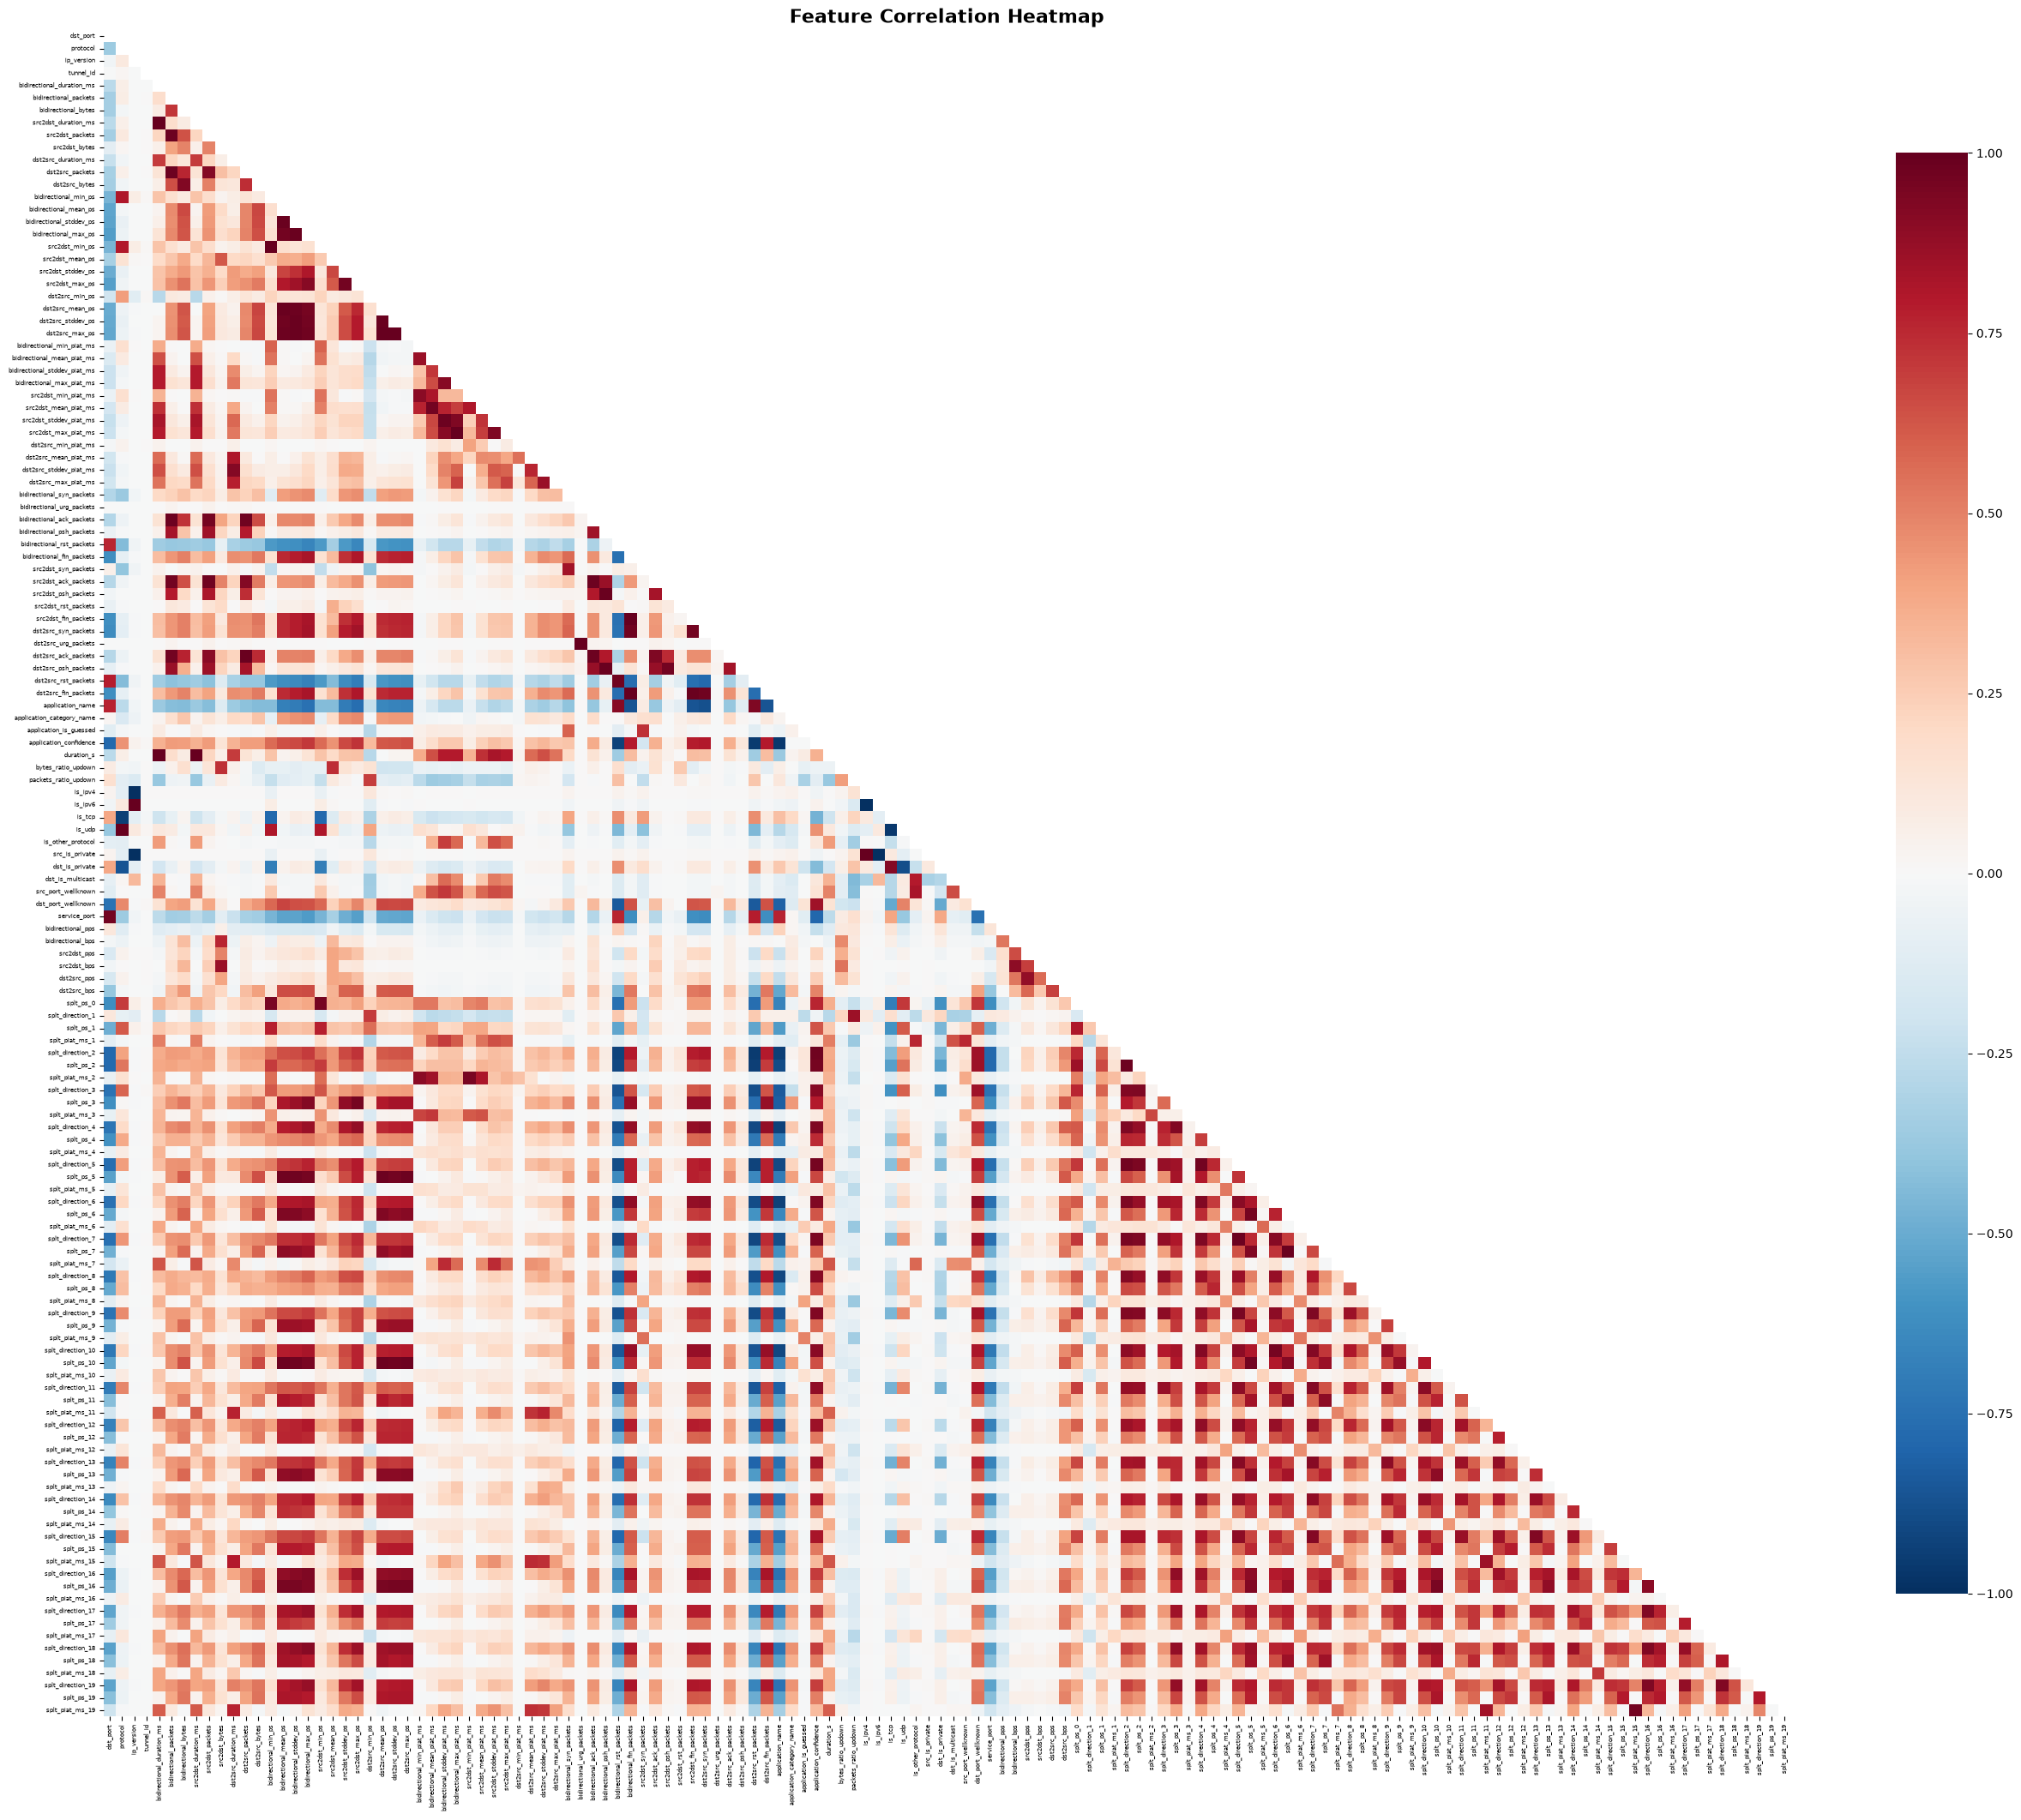

In [16]:
# Pairwise Pearson correlation of the feature candidates (also used to find redundant columns in 5.1)
corr_cols = [c for c in feature_candidates if c not in constant_cols]
corr_matrix = pd.DataFrame(np.corrcoef(ml_df[corr_cols].to_numpy(dtype=np.float64), rowvar=False),
                           index=corr_cols, columns=corr_cols)

if eda_cfg.run_eda:
    # Correlation Heatmap
    fig, ax = plt.subplots(figsize=(26, 22))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', center=0,
                square=True, linewidths=0, ax=ax,
                cbar_kws={"shrink": 0.8},
                xticklabels=True, yticklabels=True,
                vmin=-1, vmax=1)
    ax.set_title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
    ax.tick_params(axis='both', labelsize=5)
    plt.tight_layout()
    plt.show()

In [17]:
if eda_cfg.run_eda:
    # Highly correlated feature pairs
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
    pairs = upper.stack()
    high_corr_pairs = pairs[pairs.abs() > 0.95].sort_values(key=np.abs, ascending=False)

    print(f"Highly Correlated Feature Pairs (|r| > 0.95)")
    print(f"\n{len(high_corr_pairs)} pairs:\n")
    for (f1, f2), r in high_corr_pairs.items():
        print(f"{r:+.4f} {f1} - {f2}")

Highly Correlated Feature Pairs (|r| > 0.95)

88 pairs:

+1.0000 ip_version - is_ipv6
-1.0000 ip_version - is_ipv4
+1.0000 bidirectional_duration_ms - duration_s
+1.0000 bidirectional_urg_packets - dst2src_urg_packets
-1.0000 is_ipv4 - is_ipv6
+0.9998 bidirectional_min_ps - src2dst_min_ps
+0.9998 bidirectional_duration_ms - src2dst_duration_ms
+0.9998 src2dst_duration_ms - duration_s
+0.9998 bidirectional_max_piat_ms - src2dst_max_piat_ms
+0.9974 bidirectional_fin_packets - src2dst_fin_packets
+0.9973 bidirectional_fin_packets - dst2src_fin_packets
+0.9966 dst2src_stddev_ps - dst2src_max_ps
+0.9955 protocol - is_udp
-0.9955 is_ipv6 - src_is_private
+0.9955 is_ipv4 - src_is_private
-0.9955 ip_version - src_is_private
+0.9953 dst2src_mean_ps - dst2src_max_ps
+0.9913 bidirectional_psh_packets - dst2src_psh_packets
+0.9906 bidirectional_psh_packets - src2dst_psh_packets
+0.9901 bidirectional_stddev_ps - dst2src_max_ps
+0.9896 bidirectional_stddev_ps - bidirectional_max_ps
+0.9893 src2dst_f

Mean Feature Values Per Class (Technique)

                                         bidirectional_duration_ms  src2dst_packets  dst2src_packets  src2dst_bytes  dst2src_bytes  bidirectional_bps  bidirectional_pps  src2dst_mean_ps  dst2src_mean_ps  bidirectional_mean_piat_ms  dst_port  bidirectional_mean_ps
Technique                                                                                                                                                                                                                                                              
BENIGN                                                    25064.03             9.23             6.98        1721.27         645.46           38934.71             268.91           114.59            80.53                     1920.68   7129.48                 105.59
Brute force (wordlist)                                     2818.01             6.90             5.86         511.94         502.47            3439.54              43

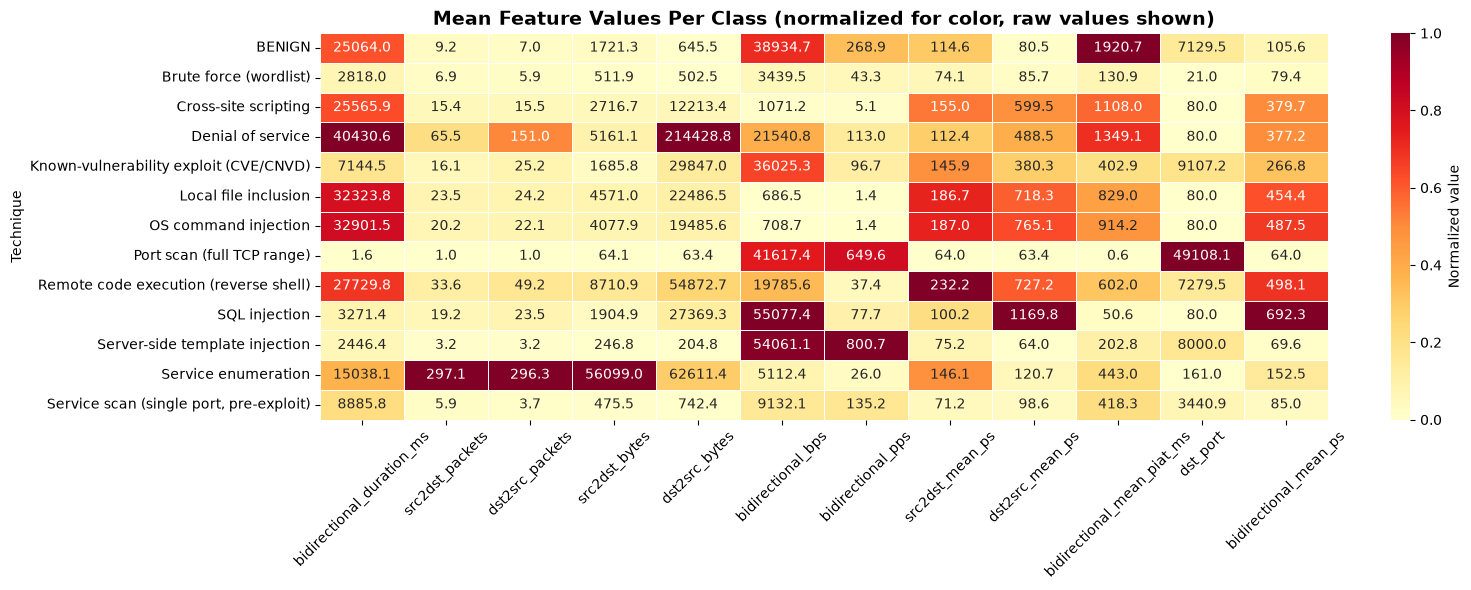

In [18]:
if eda_cfg.run_eda:
    # Summary statistics per class - mean of key features
    print(f"Mean Feature Values Per Class ({target_col})\n")
    class_means = ml_df.groupby(target_col)[key_features].mean()
    print(class_means.round(2).to_string())

    fig, ax = plt.subplots(figsize=(16, max(6, 0.4 * len(class_means))))
    scaler_viz = MinMaxScaler()
    class_means_norm = pd.DataFrame(
        scaler_viz.fit_transform(class_means),
        index=class_means.index,
        columns=class_means.columns
    )
    sns.heatmap(class_means_norm, cmap='YlOrRd', annot=class_means.round(1).values, fmt='',
                ax=ax, linewidths=0.5, cbar_kws={"label": "Normalized value"})
    ax.set_title('Mean Feature Values Per Class (normalized for color, raw values shown)',
                 fontsize=14, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

## 5. Data Engineering

### 5.1 Constant and redundant columns

Unlike the CIC-IDS2017 notebook, which lists these columns by hand, they are detected from the data.

In [19]:
if prep_cfg.drop_constant_columns:
    ml_df.drop(columns=constant_cols, inplace=True)
    tl_df.drop(columns=constant_cols, inplace=True)
    print(f"Dropped {len(constant_cols)} constant columns: {constant_cols}")

Dropped 13 constant columns: ['vlan_id', 'bidirectional_cwr_packets', 'bidirectional_ece_packets', 'src2dst_cwr_packets', 'src2dst_ece_packets', 'src2dst_urg_packets', 'dst2src_cwr_packets', 'dst2src_ece_packets', 'src_is_multicast', 'src_is_broadcast', 'dst_is_broadcast', 'splt_direction_0', 'splt_piat_ms_0']


In [20]:
redundant_to_drop = []
if prep_cfg.drop_redundant_columns:
    # |r| = 1: the column is an exact linear function of an earlier one
    # (e.g. duration_s = bidirectional_duration_ms / 1000, is_ipv6 = 1 - is_ipv4).
    kept = []
    for col in corr_cols:
        twin = next((k for k in kept if abs(corr_matrix.at[col, k]) >= 1 - 1e-6), None)
        if twin is None:
            kept.append(col)
        else:
            redundant_to_drop.append(col)
            print(f"  {col}  (|r|=1 with {twin})")

    ml_df.drop(columns=redundant_to_drop, inplace=True)
    tl_df.drop(columns=redundant_to_drop, inplace=True)
    print(f"Dropped {len(redundant_to_drop)} redundant columns")

  dst2src_urg_packets  (|r|=1 with bidirectional_urg_packets)
  duration_s  (|r|=1 with bidirectional_duration_ms)
  is_ipv4  (|r|=1 with ip_version)
  is_ipv6  (|r|=1 with ip_version)
Dropped 4 redundant columns


### 5.2 Label encoding

In [21]:
# Encode the multi-class target (binary BENIGN vs ATTACK is derived from Label downstream)
le = LabelEncoder()
le.fit(ml_df[target_col])

ml_df['label_encoded'] = le.transform(ml_df[target_col])
tl_df['label_encoded'] = le.transform(tl_df[target_col])

label_mapping = dict(zip(le.classes_.tolist(), [int(x) for x in le.transform(le.classes_)]))
print(f"Label Encoding Mapping ({target_col}):\n")
for label, code in sorted(label_mapping.items(), key=lambda x: x[1]):
    print(f"{code} - {label}")

Label Encoding Mapping (Technique):

0 - BENIGN
1 - Brute force (wordlist)
2 - Cross-site scripting
3 - Denial of service
4 - Known-vulnerability exploit (CVE/CNVD)
5 - Local file inclusion
6 - OS command injection
7 - Port scan (full TCP range)
8 - Remote code execution (reverse shell)
9 - SQL injection
10 - Server-side template injection
11 - Service enumeration
12 - Service scan (single port, pre-exploit)


### 5.3 Compact dtypes

float64 → float32 and integers to the smallest type that holds them, which roughly halves memory for the training notebooks. The absolute timestamp stays int64.

In [22]:
def compact_dtypes(df, keep=()):
    for col in df.columns:
        if col in keep:
            continue
        if pd.api.types.is_float_dtype(df[col]):
            df[col] = df[col].astype(np.float32)
        elif pd.api.types.is_integer_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='integer')
    return df


mem_before = (ml_df.memory_usage().sum() + tl_df.memory_usage().sum()) / 1e9
ml_df = compact_dtypes(ml_df)
tl_df = compact_dtypes(tl_df, keep=('bidirectional_first_seen_ms',))
mem_after = (ml_df.memory_usage().sum() + tl_df.memory_usage().sum()) / 1e9
print(f"Memory (ml + tl, without strings): {mem_before:.2f} GB -> {mem_after:.2f} GB")

Memory (ml + tl, without strings): 3.21 GB -> 1.56 GB


## 6. Correlation-Based Feature Selection (Optional)

In [23]:
# Determine feature columns
non_feature_cols_ml = ['Label', 'Technique', 'label_encoded']
feature_cols = [c for c in ml_df.columns if c not in non_feature_cols_ml]
print(f"Total feature columns: {len(feature_cols)}")

selected_feature_cols = None

if corr_cfg.enabled:
    print(f"Method: {corr_cfg.method}, Threshold: {corr_cfg.correlation_threshold}, Target: {corr_cfg.target}")

    # The label codes have no natural order, so the binary attack indicator is the default target
    if corr_cfg.target == 'binary':
        target = (ml_df['Label'] != BENIGN).astype(np.float64)
    else:
        target = ml_df['label_encoded'].astype(np.float64)

    if corr_cfg.method == 'spearman':
        # Spearman = Pearson on ranks; ranking once avoids a full feature x feature matrix
        corr_with_target = ml_df[feature_cols].rank().corrwith(target.rank())
    else:
        corr_with_target = ml_df[feature_cols].corrwith(target)
    corr_with_target = corr_with_target.dropna()
    corr_with_target_abs = corr_with_target.abs().sort_values(ascending=False)

    selected_feature_cols = corr_with_target_abs[corr_with_target_abs >= corr_cfg.correlation_threshold].index.tolist()

    print(f"\nSelected {len(selected_feature_cols)} features (|corr| >= {corr_cfg.correlation_threshold}):")
    for feat in selected_feature_cols:
        print(f"{feat} {corr_with_target[feat]:+.4f}")

    if not selected_feature_cols:
        print("WARNING: no feature reaches the threshold; downstream notebooks will use all features.")
        selected_feature_cols = None

Total feature columns: 132
Method: spearman, Threshold: 0.3, Target: binary



Selected 90 features (|corr| >= 0.3):
dst2src_min_piat_ms -0.7057
is_tcp +0.6960
dst_is_private +0.6910
is_udp -0.6738
splt_ps_0 -0.6293
protocol -0.6132
src2dst_syn_packets +0.6073
src2dst_mean_ps -0.6061
splt_ps_1 -0.6047
splt_piat_ms_7 -0.6023
splt_ps_2 -0.6006
bidirectional_min_ps -0.5936
src2dst_min_ps -0.5928
splt_ps_4 -0.5897
src2dst_min_piat_ms -0.5868
application_confidence -0.5851
src2dst_mean_piat_ms -0.5820
splt_piat_ms_9 -0.5788
dst2src_rst_packets +0.5787
splt_direction_3 -0.5757
splt_piat_ms_6 -0.5722
splt_direction_2 -0.5650
splt_ps_8 -0.5642
src2dst_max_ps -0.5628
src2dst_bps -0.5626
splt_direction_5 -0.5624
src2dst_pps -0.5609
src2dst_duration_ms -0.5606
src2dst_max_piat_ms -0.5592
bidirectional_rst_packets +0.5529
splt_piat_ms_13 -0.5528
src2dst_bytes -0.5490
splt_piat_ms_4 -0.5476
bidirectional_stddev_piat_ms -0.5468
splt_piat_ms_15 -0.5438
splt_direction_7 -0.5429
src2dst_stddev_piat_ms -0.5422
splt_direction_8 -0.5397
bidirectional_mean_ps -0.5388
application_nam

## 7. Save Prepared Data

In [24]:
if prep_cfg.save_prepared_data:
    output_dir = Path(paths_cfg.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    ml_path = output_dir / 'ml_prepared.parquet'
    ml_df.to_parquet(ml_path, index=False)
    print(f"Saved ML dataset: {ml_path}")

    tl_path = output_dir / 'tl_prepared.parquet'
    tl_df.to_parquet(tl_path, index=False)
    print(f"Saved TL dataset: {tl_path}")

    metadata = {
        'dataset': 'cyber-attacks-dataset',
        'dataset_csv': str(dataset_csv),
        'sample_rows': prep_cfg.sample_rows,
        'feature_cols': feature_cols,
        'label_mapping': label_mapping,
        'multiclass_target': target_col,
        'categorical_mappings': categorical_mappings,
        'fill_value': FILL_VALUE,
        'ip_cols': ['src_ip', 'dst_ip'],
        'time_col': 'bidirectional_first_seen_ms',
        'period_col': 'capture_id',
        'ml_shape': list(ml_df.shape),
        'tl_shape': list(tl_df.shape),
    }
    if selected_feature_cols is not None:
        metadata['selected_feature_cols'] = selected_feature_cols
        metadata['correlation_threshold'] = corr_cfg.correlation_threshold
        metadata['correlation_method'] = corr_cfg.method
        metadata['correlation_target'] = corr_cfg.target

    meta_path = output_dir / 'metadata.json'
    with open(meta_path, 'w', encoding='utf-8') as f:
        json.dump(metadata, f, indent=2)
    print(f"Saved metadata: {meta_path}")

print(f"\nNotebook runtime: {(time.time() - NOTEBOOK_T0) / 60:.1f} min")

Saved ML dataset: prepared_data/ml_prepared.parquet


Saved TL dataset: prepared_data/tl_prepared.parquet
Saved metadata: prepared_data/metadata.json

Notebook runtime: 1.0 min
